# CDAC Machine Learning — Day 8
## Problem 2: Fertilizer vs Crop Yield
### Non-Linear Modeling of Diminishing Returns & Fertilizer Toxicity

---

### Agronomic Problem Context:
In agriculture, applying fertilizer initially increases crop yield. However, past a certain threshold, additional fertilizer yields diminishing returns, and excessive fertilizer can lead to fertilizer burn/toxicity, causing yields to decrease:
$$\text{Yield} = 2.0 + 0.08 \times \text{Fertilizer} - 0.00028 \times (\text{Fertilizer}^2) + \text{Noise}$$

This inverted U-curve (parabolic arch) is a classic **Degree 2 Polynomial** relationship.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Seed and sample size
n_samples = 200
np.random.seed(2026)

fertilizer = np.random.uniform(20, 250, size=n_samples)
# Yield = 2.0 + 0.08*Fertilizer - 0.00028*(Fertilizer^2) + Noise
true_yield = 2.0 + 0.08 * fertilizer - 0.00028 * (fertilizer**2)
observed_yield = true_yield + np.random.normal(0, 0.8, size=n_samples)

df = pd.DataFrame({
    "fertilizer_kg_ha": fertilizer.round(1),
    "crop_yield_tons": observed_yield.round(2),
})

# Test plots for prediction
new_farm_plots = pd.DataFrame({
    "fertilizer_kg_ha": [50.0, 140.0, 220.0]
})

print(f"Generated {len(df)} farm observations.")
display(df.head())


Generated 200 farm observations.


,fertilizer_kg_ha,crop_yield_tons
0,70.4,6.86
1,115.0,7.05
2,244.6,4.50
3,40.4,5.12
4,130.2,7.96


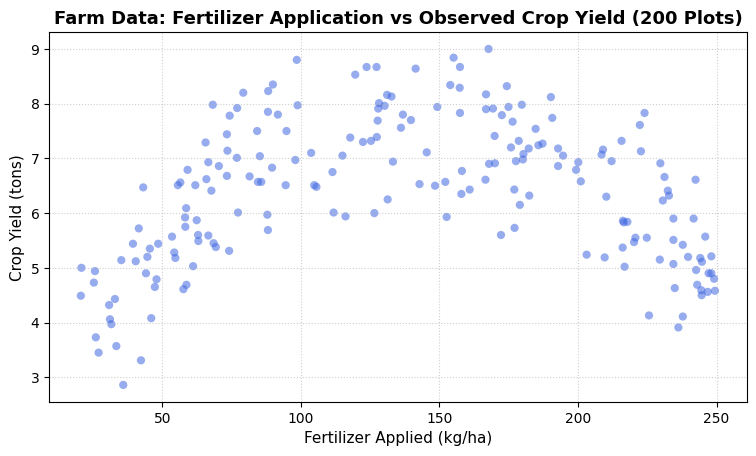

In [2]:
# Visualize raw scatter data
plt.figure(figsize=(9, 4.8))
plt.scatter(df["fertilizer_kg_ha"], df["crop_yield_tons"], color="royalblue", alpha=0.55, s=35, edgecolors="none")
plt.title("Farm Data: Fertilizer Application vs Observed Crop Yield (200 Plots)", fontsize=13, fontweight="bold")
plt.xlabel("Fertilizer Applied (kg/ha)", fontsize=11)
plt.ylabel("Crop Yield (tons)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


---
## Model Comparison Across Polynomial Degrees (1 to 4)
We evaluate how Linear, Quadratic, Cubic, and Quartic models perform on this curved dataset.


In [3]:
X = df[["fertilizer_kg_ha"]]
y = df["crop_yield_tons"]

degree_metrics = []
for deg in [1, 2, 3, 4]:
    model = make_pipeline(PolynomialFeatures(degree=deg, include_bias=False), LinearRegression())
    model.fit(X, y)
    y_pred = model.predict(X)
    
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = r2_score(y, y_pred)
    
    diagnosis = "Severe Underfitting" if deg == 1 else "Optimal Bell Curve" if deg == 2 else "Diminishing Returns"
    degree_metrics.append({
        "Degree": deg,
        "Formula Type": f"Degree {deg}",
        "RMSE": round(rmse, 4),
        "R2_Score": round(r2, 4),
        "Diagnosis": diagnosis
    })

df_metrics = pd.DataFrame(degree_metrics)
display(df_metrics)


,Degree,Formula Type,RMSE,R2_Score,Diagnosis
0,1,Degree 1,1.2910,0.0096,Severe Underfitting
1,2,Degree 2,0.8191,0.6013,Optimal Bell Curve
2,3,Degree 3,0.8163,0.6040,Diminishing Returns
3,4,Degree 4,0.8162,0.6041,Diminishing Returns


---
## Final Degree 2 Model Training & Parameter Extraction


In [4]:
final_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
final_model.fit(X, y)

lr_step = final_model.named_steps["linearregression"]
b0 = lr_step.intercept_
b1, b2 = lr_step.coef_

print("=" * 65)
print("Fitted Quadratic Equation (Degree 2):")
print(f"  Yield = {b0:.4f} + ({b1:.5f} * Fertilizer) + ({b2:.7f} * Fertilizer²)")
print("=" * 65)
print(f"Intercept (b0):           {b0:.4f}")
print(f"Linear Coeff (b1):        {b1:.5f}")
print(f"Quadratic Coeff (b2):     {b2:.7f}")


Fitted Quadratic Equation (Degree 2):
  Yield = 2.5576 + (0.07091 * Fertilizer) + (-0.0002491 * Fertilizer²)
Intercept (b0):           2.5576
Linear Coeff (b1):        0.07091
Quadratic Coeff (b2):     -0.0002491


---
## Predictions for New Farm Plots
We predict yields for 3 new farms:
- **50.0 kg/ha**: Light fertilizer (Under-fertilized)
- **140.0 kg/ha**: Near agronomic optimum (Peak Yield)
- **220.0 kg/ha**: Heavy over-fertilization (Toxicity / Burn)


In [5]:
predicted_yields = final_model.predict(new_farm_plots)
new_farm_plots_with_preds = new_farm_plots.copy()
new_farm_plots_with_preds["predicted_yield_tons"] = predicted_yields.round(2)
display(new_farm_plots_with_preds)


,fertilizer_kg_ha,predicted_yield_tons
0,50.0,5.48
1,140.0,7.60
2,220.0,6.10


---
## Final Visualization: Actual Data vs Polynomial Fit vs Linear Baseline


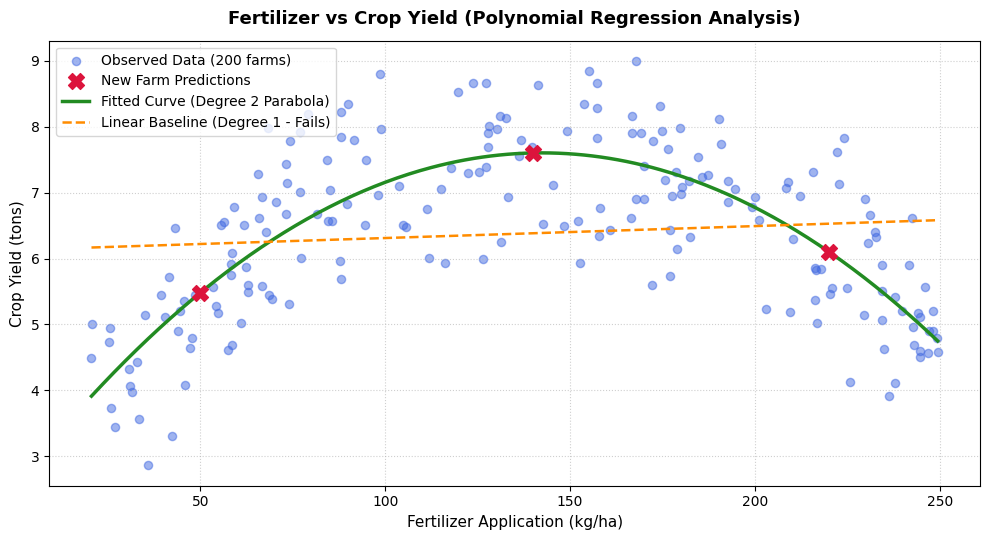

In [6]:
x_smooth = pd.DataFrame({"fertilizer_kg_ha": np.linspace(df["fertilizer_kg_ha"].min(), df["fertilizer_kg_ha"].max(), 300)})
y_smooth = final_model.predict(x_smooth)

linear_baseline = LinearRegression().fit(X, y)
y_linear_smooth = linear_baseline.predict(x_smooth)

plt.figure(figsize=(10, 5.5))
plt.scatter(df["fertilizer_kg_ha"], df["crop_yield_tons"], color="royalblue", alpha=0.5, s=35, label="Observed Data (200 farms)")
plt.scatter(new_farm_plots["fertilizer_kg_ha"], predicted_yields, color="crimson", marker="X", s=130, zorder=6, label="New Farm Predictions")
plt.plot(x_smooth["fertilizer_kg_ha"], y_smooth, color="forestgreen", linewidth=2.5, label="Fitted Curve (Degree 2 Parabola)")
plt.plot(x_smooth["fertilizer_kg_ha"], y_linear_smooth, color="darkorange", linestyle="--", linewidth=1.8, label="Linear Baseline (Degree 1 - Fails)")

plt.title("Fertilizer vs Crop Yield (Polynomial Regression Analysis)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Fertilizer Application (kg/ha)", fontsize=11)
plt.ylabel("Crop Yield (tons)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("fertilizer_crop_yield_polynomial_fit.png", dpi=150)
plt.show()
